In [1]:
import numpy as np
import time
from copy import deepcopy
import batoid

%config InlineBackend.figure_format = 'retina' # increase quality but slower

In [2]:
import matplotlib.pyplot as plt

In [78]:
pxo = 0#0.00001
pyo = 0#0.00001

In [77]:
0.983629+0.237581

1.22121

In [79]:
def telescopeCreation(WL):
    #global WL
    global telescope, M1

    global outter1, inner1, outterD
    
    #WL = 650e-9
    
    R1, conic1, inner1, outter1 = -16.256, -0.9953569, 1.38, 6.42
    #M1coord = defineCoordinate(anglX=0.0035, anglY=0.0035, anglZ=0, posX=200e-6, posY=200e-6, posZ=200e-6).local()
    M1coord = defineCoordinate(posX=pxo, posY=pyo).local()
    M1 = optic('M1',type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(width=0.3, height=4)
                                                                                                                             
    R2, conic2, outter2 = -1.660575, -1.566503, 0.7147252
    #M2coord = defineCoordinate(anglX=-0.00878, anglY=0.0116, anglZ=0, posX=-0.2014e-3, posY=0.8984e-3, posZ=-7.400+191.3e-6).local()
    M2coord = defineCoordinate(anglX=0, posZ=-7.400).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()

    R3, conic3, outter3 = -1.830517, -0.718069, 0.920733
    M3coord = defineCoordinate(posZ=+0.050).local()
    M3 = optic('M3', type='Quadric', RoC=R3, conic=conic3, outDiam=outter3, coordSys=M3coord).mirror()

    outter4 = 0.0991468
    M4coord = defineCoordinate(posZ=-0.983629).local()
    M4 = optic('M4', outDiam=outter4, coordSys=M4coord).flatMirror()

    outterD = 0.9
    Dcoord = defineCoordinate(posZ=0.237581).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()

    telescope = build.compoundOptic(M1, M2, M3, M4, D, 
                                    pupilSize=6.46, backDist=7.5,
                                    EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [80]:
def showLayout(show='2D'):
    start = time.time()

    ## Field bias + Number of rays per field`
    nbOfRaysPerField = 6 # should be even

    ## Rays of central field
    anglX, anglY = 0, 0
    anglY += fieldBias
    field0 = layout.rayBundle(telescope, WL, M1.inDiam, M1.outDiam, anglX, anglY, nbOfRaysPerField)

    ## Rays of central field 1
    anglX, anglY = 0, -0.043
    anglY += fieldBias
    field1 = layout.rayBundle(telescope, WL, M1.inDiam, M1.outDiam, anglX, anglY, nbOfRaysPerField)

    ## Rays of central field 2
    anglX, anglY = 0, 0.043
    anglY += fieldBias
    field2 = layout.rayBundle(telescope, WL, M1.inDiam, M1.outDiam, anglX, anglY, nbOfRaysPerField)

    ## Optic's lines
    opticsContours = layout.getAllLines(telescope)
    #opticsContours3D = deepcopy(opticsContours) ## important to make copy of the chain because it is nested (one use 'destroys' it)

    if show.casefold() == '2d':
        ## 2D visualization
        layout.visualized2D(len(field0), *opticsContours,
                            *field0, *field1, *field2)
    elif show.casefold() == '3d':
        ## 3D visualization
        layout.visualized3D(len(field0), *opticsContours,
                            *field0, *field1, *field2)
    
    print('2D and/or 3D calculation + plot time', np.round(time.time()-start, decimals=5), 's')

In [81]:
def showSpotDiagram(WL, fieldX=0, fieldY=0):
    ## Incoming rays
    nbOfRays = 1e4
    fieldY += fieldBias
    rays0 = ray(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL, nbOfRays=nbOfRays).fromPupil(type='grid')
    rays = rays0.copy()

    ## Trace rays + deleting vignetted ones
    telescope.trace(rays, reverse=False)
    rays = ray.deleteVignettedRays(rays)
    
    ## Some details
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    print('F/# in Image Space     :', np.round(infoTelescope.paraxialWorkingFNumber(), decimals=5), '      -> ZEMAX : 14.94606')
    print('Paraxial Working F/#   :', np.round(infoTelescope.FNumber(), decimals=5), '      -> ZEMAX : 14.94606')
    print('Working F/#            :', np.round(infoTelescope.workingFNumber(offFieldY=fieldBias), decimals=5), '      -> ZEMAX : 15.09287')
    print('NA in Image Space      :', np.round(infoTelescope.NA(), decimals=8), '    -> ZEMAX : 0.03343492')
    print('Effective Focal Length :', -np.round(infoTelescope.EFFL() * 1000, decimals=2), 'mm', '  -> ZEMAX : -96551.57 mm')
    print('XP position            :', np.round(batoid.analysis.exitPupilPos(optic=telescope, wavelength=WL)[-1]-telescope.items[-1].coordSys.origin[-1],
                                               decimals=6) * 1000, 'mm', '  -> ZEMAX : -1221.202 mm')
    print('Airy radius            :', np.round(airyR:=infoTelescope.airyRadius(offFieldY=fieldBias), decimals=4), 'µm', '    -> ZEMAX : 11.969 µm')
    print('Out/In Flux            :', np.round(np.sum(rays.flux)/np.sum(rays0.flux)*100, decimals=2), '%')
    print('Strehl Ratio           :', np.round(infoTelescope.strehlRatio(), decimals=4), '         -> ZEMAX : 0.991')

    ## Plot Spot Diagram
    #return spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)
    plot.spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)

In [82]:
def showWavefrontMap(WL):
    fieldX, fieldY = 0, fieldBias
    #fieldX, fieldY =-0.070250,-3.5e-4

    ## Wavefront
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    WF = infoTelescope.wavefront(npx=1024, background=False)

    ## Wavefront details + Plot
    plot.wavefront(WF, WL, [fieldX, fieldY-fieldBias])

    ## Wavefront corrected + Plot
    corrWF, removed = correction.removeTiltWavefront(WF, WL, tiltX=False, tiltY=True)
    plot.wavefront(corrWF, WL, [fieldX, fieldY-fieldBias])
    print(f'Tilt Removed:  X = {np.round(removed[0], decimals=4)}, Y = {np.round(removed[1], decimals=4)} waves\n')

    
    ## Noll Zernike wavefront
    print('Zernikes :\n')
    Znk = infoTelescope.wavefrontZnk(npx=128, jmax=13, show=True)  #NB: show should be False for jmax > 13

In [83]:
def showPSF(WL, show3D=False):  
    start = time.time()
    
    ## FFT PSF
    fieldX, fieldY = 0, fieldBias
    #fieldX, fieldY = -0.070250,-3.5e-4

    if show3D:
        pad = 2
    else:
        pad = 16
    
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=pad) # pad: pixelization / npx: accuracy

    ## PSF Plots
    if show3D:
        plot.psf3D(PSF, infoTelescope.airyRadius())
        print(f'Strehl Ratio : {StehlRatio:.3f}')
    else:
        plot.psf2D(PSF, infoTelescope.airyRadius())
        plot.psfCrossSection(PSF, infoTelescope.airyRadius(), WL, [fieldX, fieldY-fieldBias], StehlRatio, axis='X')


    print('\nPSF calculation+plot time', np.round(time.time()-start, decimals=5))

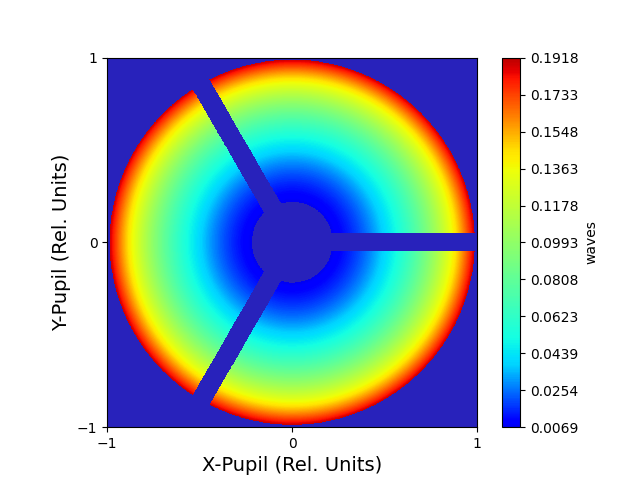

09/15/2025
0.65 µm at 0.0, 0.0 (deg)
Peak to valley = 0.185 waves, RMS = 0.0531 waves


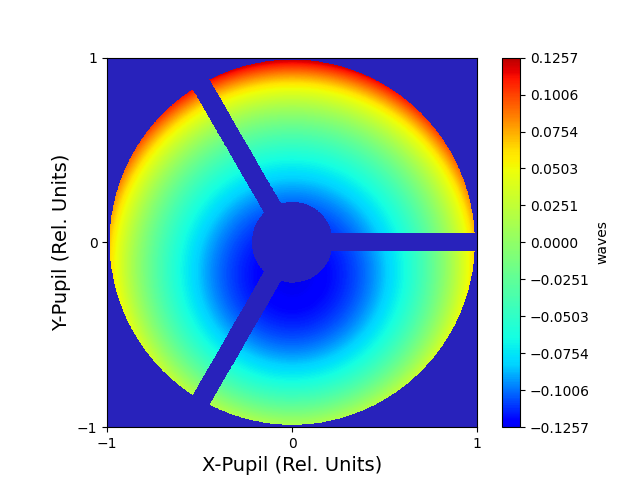

09/15/2025
0.65 µm at 0.0, 0.0 (deg)
Peak to valley = 0.2514 waves, RMS = 0.0601 waves
Tilt Removed:  X = 0.0, Y = 0.0701 waves

Zernikes :

RMS (to chief)    :    0.035165288 (waves)

Z   1      0.089132938  :      1
Z   2     -0.000000000  :      4^(1/2) (P) * COS (A)
Z   3      0.000000000  :      4^(1/2) (P) * SIN (A)
Z   4      0.056065878  :      3^(1/2) (2P^2-1)
Z   5      0.000000000  :      6^(1/2) (p^2) * SIN (2A)
Z   6     -0.000000000  :      6^(1/2) (p^2) * COS (2A)
Z   7     -0.000000000  :      8^(1/2) (3p^3 - 2p) * SIN (A)
Z   8      0.000000000  :      8^(1/2) (3p^3 - 2p) * COS (A)
Z   9     -0.000000000  :      8^(1/2) (p^3) * SIN (3A)
Z  10     -0.000000000  :      8^(1/2) (p^3) * COS (3A)
Z  11      0.003718237  :      5^(1/2) (6p^4-6p^2+1)
Z  12      0.000000000  :      10^(1/2) (4p^4-3p^2) * COS (2A)
Z  13     -0.000000000  :      10^(1/2) (4p^4 - 3p^2) * SIN (2A)


2D and/or 3D calculation + plot time 1.41378 s
F/# in Image Space     : 14.94432       -> ZEMAX : 14.94606
Paraxial Working F/#   : 14.94788       -> ZEMAX : 14.94606
Working F/#            : 14.94432       -> ZEMAX : 15.09287
NA in Image Space      : 0.03345752     -> ZEMAX : 0.03343492
Effective Focal Length : -96563.27 mm   -> ZEMAX : -96551.57 mm
XP position            : -1224.532 mm   -> ZEMAX : -1221.202 mm
Airy radius            : 11.8476 µm     -> ZEMAX : 11.969 µm
Out/In Flux            : 87.34 %
Strehl Ratio           : 0.8671          -> ZEMAX : 0.991


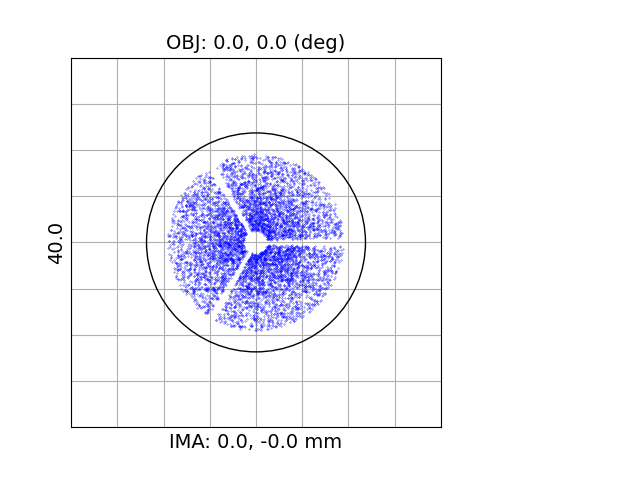

09/15/2025
Units are µm. Airy Radius: 11.848 µm. Wavelength: 0.65 µm.
RMS radius :    5.935
GEO radius :    9.59
Scale bar  :   40.0    Reference : Centroid



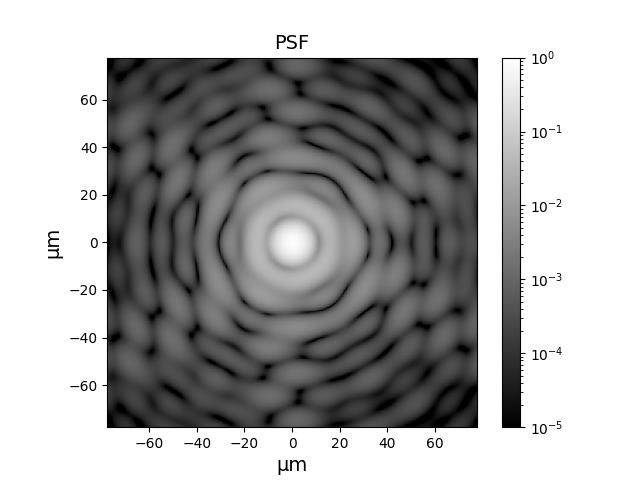

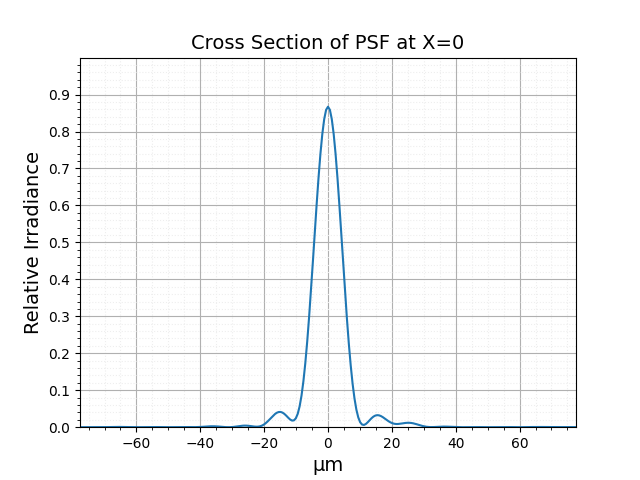

09/15/2025
0.65 µm at 0.0, 0.0 (deg)
Image width is 155.37 µm
Strehl ratio: 0.867

PSF calculation+plot time 0.92596


In [85]:
WL = 650e-9
def main():
    %run Batoid4LOFT.ipynb

    plt.close('all')

    global fieldBias
    #fieldBias = 0.0
    fieldBias = 0.0

    telescopeCreation(WL)

    ## Select what you want to see
    showWavefrontMap(WL)
    showLayout(show='2D')
    showSpotDiagram(WL, fieldX=0, fieldY=0)
    showPSF(WL, show3D=False)

if __name__=='__main__':
    main()

In [18]:
import poppy

In [19]:
infoTelescope = details(telescope)
WF = infoTelescope.wavefront(npx=1024, background=False)

e = poppy.zernike.decompose_opd(WF)

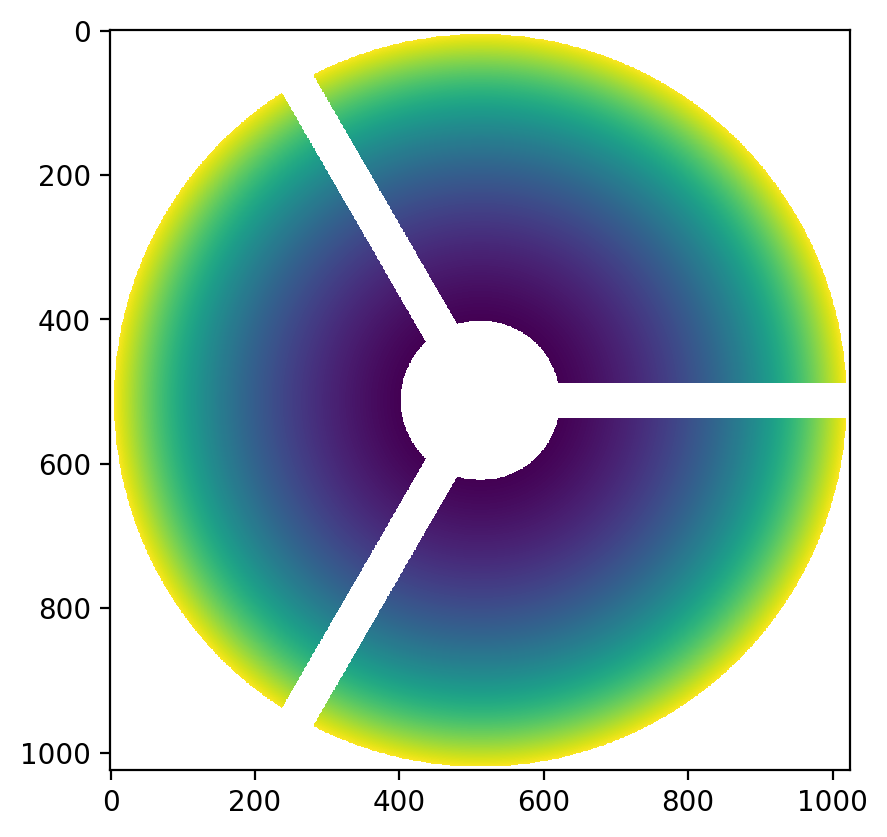

In [41]:
plt.imshow(WF)

In [27]:
e

[0.0959593404210714,
 0.0002216806789847327,
 0.00018760379358960505,
 0.058648596934955624,
 5.307962359198011e-07,
 3.48396908393608e-05,
 0.000546050860460306,
 0.0005537315522478309,
 1.1848184066478783e-07,
 -0.00852066310370577,
 -0.0022944564970703908,
 -3.455017670441285e-05,
 4.0354777234410966e-05,
 -5.3271670706874803e-05,
 -3.7248837875981995e-05]

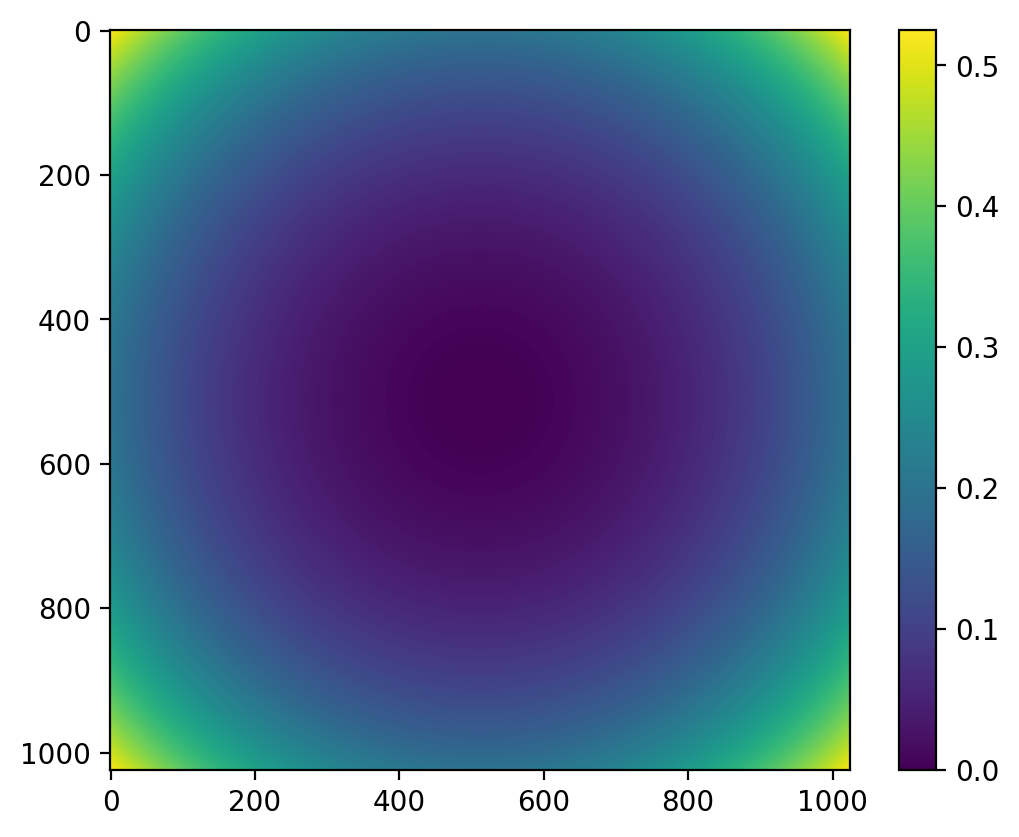

In [67]:
y = WF.data
m = y.astype(int)
plt.imshow(y)
plt.colorbar()

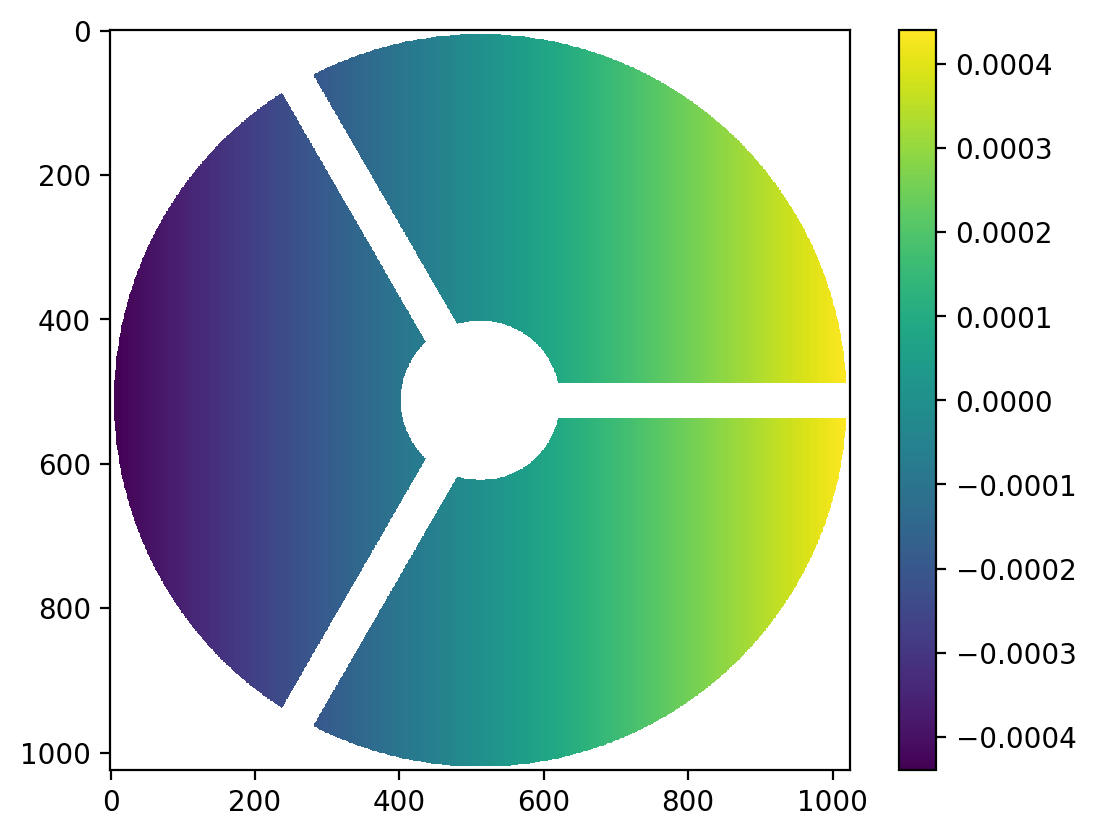

In [68]:
plt.imshow(0.0002216806789847327*poppy.zernike.zernike1(2, npix=1024)*WF/WF.data)
plt.colorbar()

In [31]:
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=WL)
PSF1, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
PSF1

array([[6.03293625e-07, 5.71476029e-07, 5.28486669e-07, ...,
        6.18160928e-07, 6.26836245e-07, 6.22008169e-07],
       [5.96930546e-07, 5.65411172e-07, 5.23040925e-07, ...,
        6.12988143e-07, 6.20936263e-07, 6.15700271e-07],
       [5.78448808e-07, 5.47800824e-07, 5.07233816e-07, ...,
        5.97953187e-07, 6.03790973e-07, 5.97373958e-07],
       ...,
       [5.49646422e-07, 5.20374477e-07, 4.82635599e-07, ...,
        5.74488913e-07, 5.77042965e-07, 5.68797506e-07],
       [5.78448808e-07, 5.47800824e-07, 5.07233816e-07, ...,
        5.97953187e-07, 6.03790973e-07, 5.97373958e-07],
       [5.96930546e-07, 5.65411172e-07, 5.23040925e-07, ...,
        6.12988143e-07, 6.20936263e-07, 6.15700271e-07]])

In [102]:
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=WL)
PSF2, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
PSF2

array([[6.03293625e-07, 5.71476029e-07, 5.28486669e-07, ...,
        6.18160928e-07, 6.26836245e-07, 6.22008169e-07],
       [5.96930546e-07, 5.65411172e-07, 5.23040925e-07, ...,
        6.12988143e-07, 6.20936263e-07, 6.15700271e-07],
       [5.78448808e-07, 5.47800824e-07, 5.07233816e-07, ...,
        5.97953187e-07, 6.03790973e-07, 5.97373958e-07],
       ...,
       [5.49646422e-07, 5.20374477e-07, 4.82635599e-07, ...,
        5.74488913e-07, 5.77042965e-07, 5.68797506e-07],
       [5.78448808e-07, 5.47800824e-07, 5.07233816e-07, ...,
        5.97953187e-07, 6.03790973e-07, 5.97373958e-07],
       [5.96930546e-07, 5.65411172e-07, 5.23040925e-07, ...,
        6.12988143e-07, 6.20936263e-07, 6.15700271e-07]])

In [113]:
from scipy.stats import entropy

s=entropy(PSF1)+entropy(PSF1, qk=PSF2)

In [110]:
r = np.arange(0,2048,1)

In [111]:
len(r)

2048

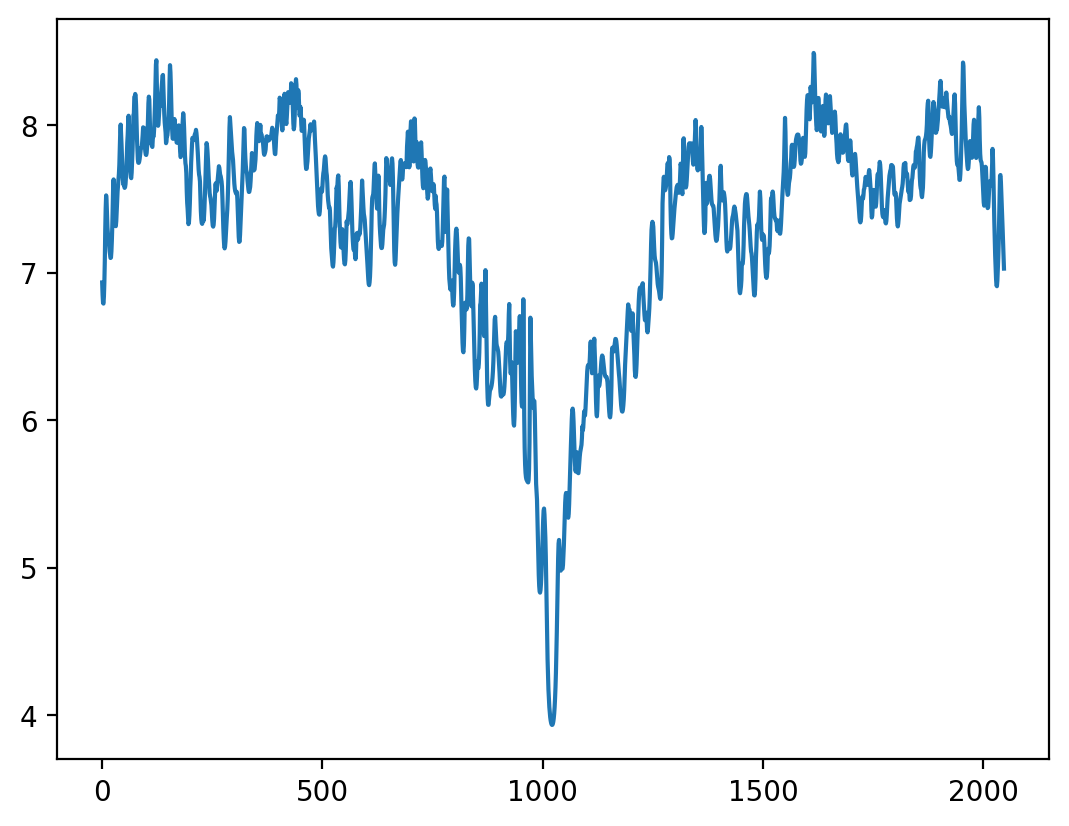

In [127]:
%matplotlib inline
plt.plot(r,s)

plt.show()

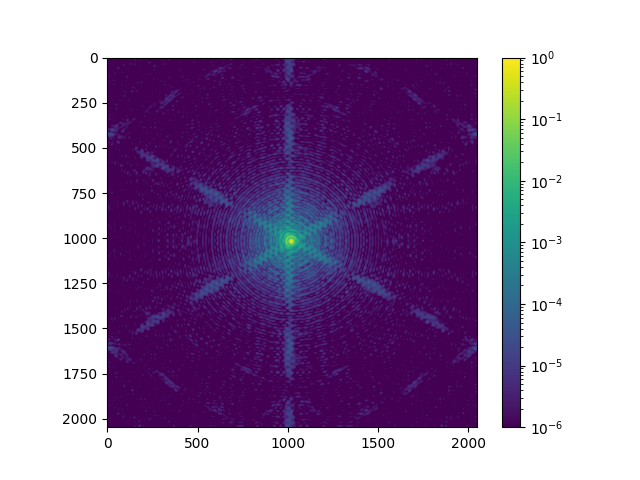

In [89]:
fig, ax = plt.subplots()
PSFax = ax.imshow(PSF, cmap='viridis', norm=mcolors.LogNorm(vmin=1e-6, vmax=1))
cbar2 = fig.colorbar(PSFax)

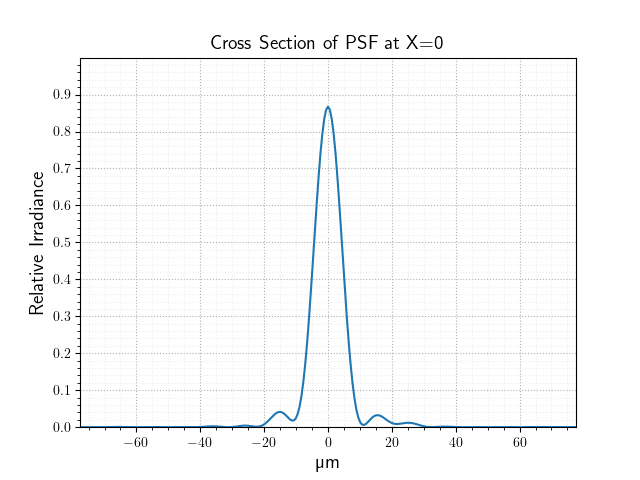

07/02/2025
0.65 µm at 0.0, 0.0 (deg)
Image width is 155.37 µm
Strehl ratio: 0.867


In [289]:
#telescopeCreation(WL)
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=WL)
PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
plot.psfCrossSection(PSF, infoTelescope.airyRadius(), WL, [0, 0], StehlRatio, axis='X')

In [116]:
pxSize=plot.findPxSize(PSF,  infoTelescope.airyRadius())

In [117]:
x = np.linspace(-1024*pxSize, 1024*pxSize, 2048)

In [129]:
y = PSF[1024, :]

In [140]:
x

array([-692.50272096, -691.8261184 , -691.14951584, ...,  691.14951584,
        691.8261184 ,  692.50272096])

In [347]:
infoTelescope = details(telescope, fieldX=0, fieldY=fieldBias, wavelength=WL)
WF = infoTelescope.wavefront(npx=128, background=False)

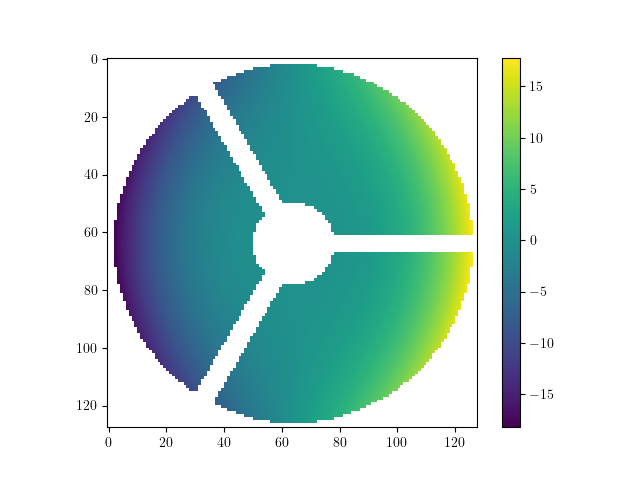

In [348]:
fig, ax = plt.subplots()
WFax = ax.imshow(WF, cmap='viridis')
cbar = fig.colorbar(WFax)

In [349]:
WFf = WF.filled(fill_value=0)

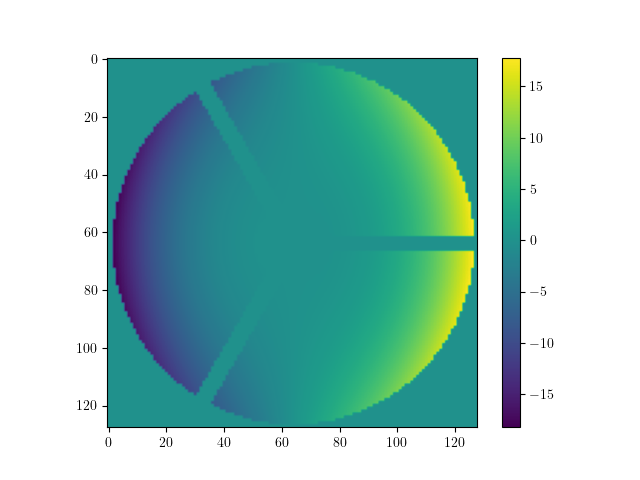

In [350]:
fig, ax = plt.subplots()
WFfax = ax.imshow(WFf, cmap='viridis')
cbar = fig.colorbar(WFfax)

In [345]:
np.savetxt('psf1d.txt', (x,y))

In [136]:
p30 = np.poly1d(np.polyfit(x, y, 3))

In [137]:
_ = plt.plot(x, y, '.', x, p30(x), '--')

In [251]:
from numpy.fft import ifftshift, fft2, fftshift

In [356]:
def PSFcalc(complx_pupil):
    PSF = ifftshift(fft2(fftshift(complx_pupil), s=[1024,1024])) 
    PSF = (np.abs(PSF))**2 #or PSF*PSF.conjugate()
    PSF = PSF/PSF.sum() #normalizing the PSF
    return PSF

/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_68735/3689548758.py:1: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



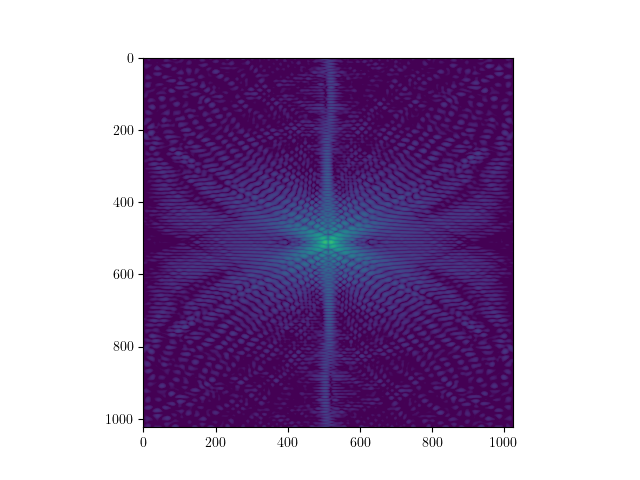

In [357]:
fig, ax = plt.subplots()
#ax_cb = ax_cb = fig.add_subplot()
WFax = ax.imshow(PSFcalc(WFf), cmap='viridis', norm=mcolors.LogNorm(vmin=1e-8, vmax=1))
cbar2 = fig.colorbar(WFfax)

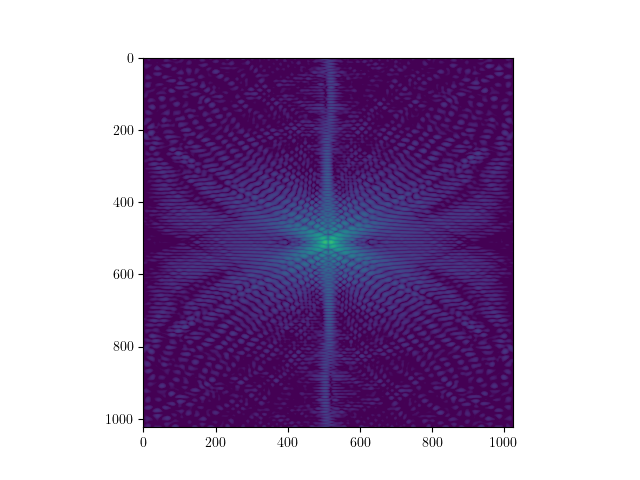

In [364]:
fig, ax = plt.subplots()
#ax_cb = ax_cb = fig.add_subplot()
WFax = ax.imshow(PSFcalc(WFf), cmap='viridis', norm=mcolors.LogNorm(vmin=1e-8, vmax=1))
cbar2 = fig.colorbar(WFfax)

In [106]:
plot.findPxSize(PSF,  infoTelescope.airyRadius())

0.5063154961375447

In [40]:
PSF[1024][1024]

0.8842719446951695

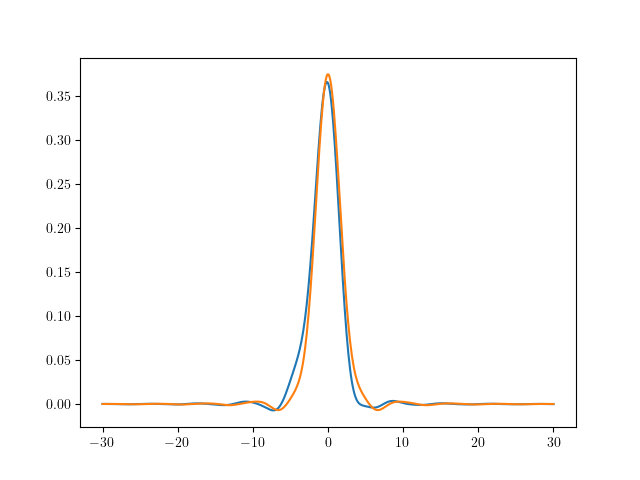

In [97]:
import numpy as np
import scipy.special as sp
import matplotlib.pyplot as plt
plt.matplotlib.rc('text', usetex = True)
plt.matplotlib.rc('grid', linestyle = 'dotted')
plt.matplotlib.rc('figure', figsize = (6.4,4.8)) # (width,height) inches
x = np.linspace(-30, 30, 500)
#for v in range(0, 6, 2):
    #plt.plot(x, sp.jv(v, x))
plt.figure()
plt.plot(x, ((sp.jv(1, x)/x)**2)+(sp.jv(2,x+1)/(x+1)**2))
plt.plot(x, ((sp.jv(1, x)/x)**2)+(sp.jv(2,x)/(x)**2))
plt.show()


In [10]:
def showPSFpc(source, show3D=False):  
    start = time.time()
    
    ## FFT PSF
    fieldX, fieldY = 0, fieldBias

    if show3D:
        pad = 2
    else:
        pad = 16
    
    for i in source:
        infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=i)
        PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=pad) # pad: pixelization / npx: accuracy
    
        ## PSF Plots
        if show3D:
            plot.psf3D(PSF, infoTelescope.airyRadius())
            print(f'Strehl Ratio : {StehlRatio:.3f}')
        else:
            plot.psf2D(PSF, infoTelescope.airyRadius())
            plot.psfCrossSection(PSF, infoTelescope.airyRadius(), WL, [fieldX, fieldY-fieldBias], StehlRatio,     axis='X')


    print('\nPSF calculation+plot time', np.round(time.time()-start, decimals=5))

In [11]:
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=468e-9)
infoTelescope.airyRadius() 

#plot.psf2D(PSF1+PSF2, infoTelescope.airyRadius())

NameError: name 'details' is not defined

In [12]:
infoTelescope650.spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)

NameError: name 'infoTelescope650' is not defined

In [13]:
def polychromsum(wave, tput, cwav):
    wsum = []
    psum = []
    telescope = telescopeCreation(cwav)
    fieldX, fieldY = 0, fieldBias
    for i in range(len(wave)):

                infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=wave[i])
                WF = infoTelescope.wavefront(npx=1024, background=False)
                sWF = tput[i]*WF.data
                wsum.append(sWF)
                PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16) 
                sPSF = tput[i]*PSF
                psum.append(sPSF)

    Wsum = np.sum(wsum, axis=0)
    Psum = np.sum(psum, axis=0)
    plot.wavefront(Wsum, cwav, [fieldX, fieldY-fieldBias])
    plot.psf2D(Psum, 8.530300822250688)#infoTelescope.airyRadius())


In [14]:
polychromsum([468e-9,470e-9], [0.1,0.9], 690e-9)

NameError: name 'defineCoordinate' is not defined

In [15]:
infoTelescope.airyRadius()

NameError: name 'infoTelescope' is not defined

In [16]:
plot.wavefront(f, 690e-9, [0, 0])

NameError: name 'plot' is not defined

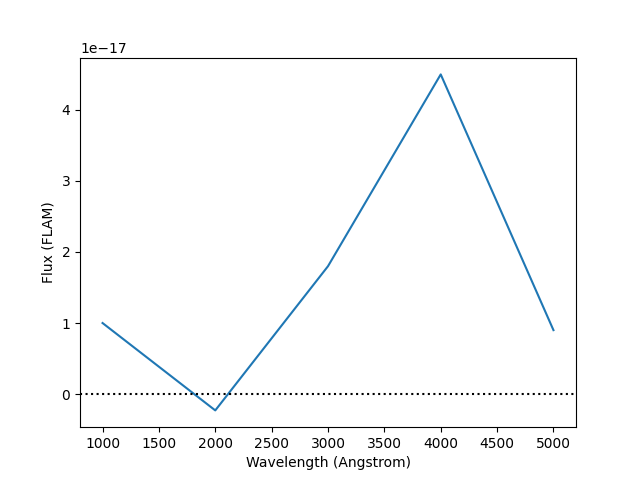

In [ ]:
from synphot import SourceSpectrum, units
from synphot.models import Empirical1D
wave = [1000, 2000, 3000, 4000, 5000]  # Angstrom
flux = [1e-17, -2.3e-18, 1.8e-17, 4.5e-17, 9e-18] * units.FLAM
sp = SourceSpectrum(Empirical1D, points=wave, lookup_table=flux, keep_neg=True)
sp.plot(flux_unit=units.FLAM)
plt.axhline(0, color='k', ls=':')

In [148]:
plt.imshow(PSF)


In [267]:
PSF = np.array(PSF)

TypeError: Image data of dtype object cannot be converted to float

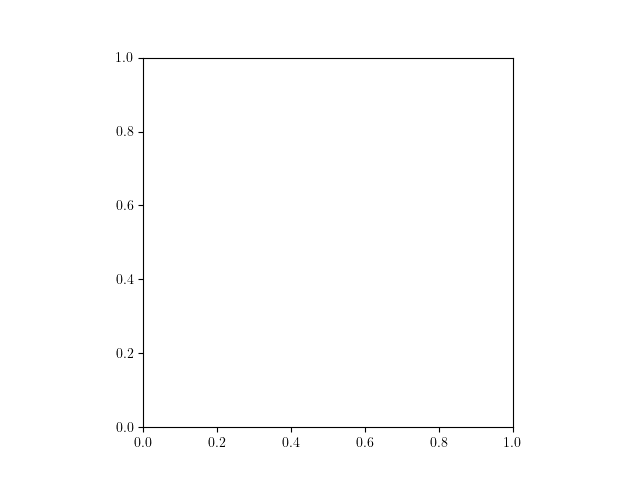

In [268]:
fig, ax = plt.subplots()
PSFax = ax.imshow(PSF, cmap='gray', norm=mcolors.LogNorm(vmin=1e-5, vmax=1))

In [200]:
from scipy.fft import fft2

In [213]:
Z = fft2(z2)

In [215]:
Z = np.real(Z)

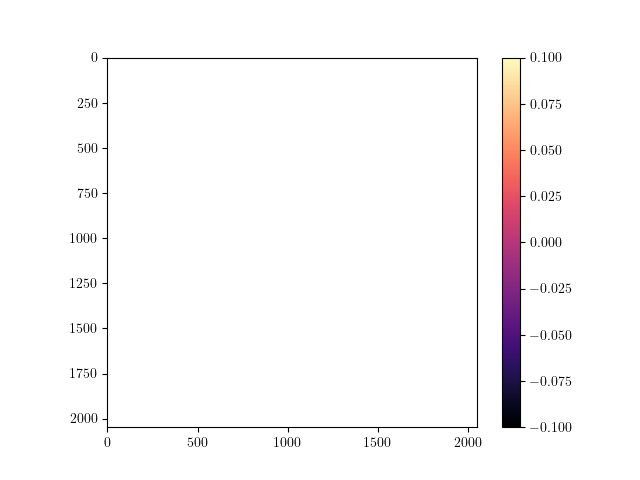

In [216]:
fig, ax = plt.subplots()
Zax = ax.imshow(Z, cmap='magma')
cbar = fig.colorbar(Zax)

In [212]:
Z[1024,1024]

3.288385189148535e-16

In [198]:
import poppy.zernike
z2 = poppy.zernike.zernike1(2, npix=2048)

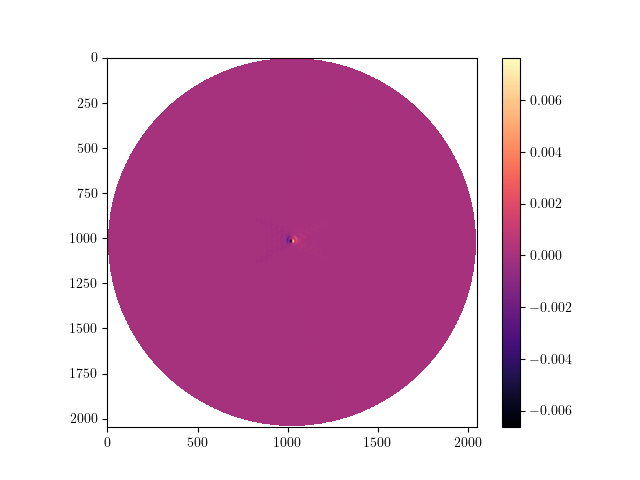

In [199]:
fig, ax = plt.subplots()
PSFaxp = ax.imshow(z2*PSF, cmap='magma')
cbar = fig.colorbar(PSFaxp)

In [222]:
WF

NameError: name 'WF' is not defined